# Group 2 — Problem 7: Polynomial & Big-Integer Multiplication
Integrated notebook: Devesh (V1/V2), Maryam (V3), Fatema (V4/V5), Tara section (tests and benchmarks).

Coefficient arrays are **ascending powers**: `[1,5,2,3]` represents `1+5x+2x²+3x³`.

# START HERE — How to run and verify this notebook

## 1. Setup (Mac / Windows / Linux)
1. Extract the complete ZIP into a single folder. Keep `tara_runtime.csv` and `tara_precision_stress.csv` next to the notebook so the saved-result charts work on any machine.
2. Open Terminal (Mac/Linux) or PowerShell (Windows) in that folder.
3. Optional virtual environment: `python3 -m venv .venv` then Mac/Linux `source .venv/bin/activate` or Windows `.venv\Scripts\activate`.
4. Install packages: `python -m pip install notebook numpy matplotlib pandas`.
5. Start Jupyter: `python -m notebook`. Open this `.ipynb` file.
6. Select the Python 3 kernel and choose **Kernel → Restart & Run All** (or **Run → Run All Cells**, depending on Jupyter version).

## 2. Expected outputs / pass criteria
- **Worked polynomial example:** all V1–V5 should print exactly `[3, 19, 27, 24, 24, 7, 6]` for `[1,5,2,3] × [3,4,1,2]`.
- **Automated tests:** final line should read `All cross-algorithm correctness comparisons passed`; no `AssertionError`.
- **Big-integer carry propagation:** `Result: 6966893`, matching `3251 × 2143`.
- **Benchmark cell:** printed rows for sizes 16, 64, 256, 1024, 2048 and each of five algorithms, with measured seconds and machine details. **Numbers depend on your computer**; do not expect identical timings. This is potentially slow, especially V1/V2 with `tracemalloc`.
- **Precision stress:** prints mismatch counts and maximum coefficient error for FFT at 10^6, 10^7, 10^8. **Nonzero mismatches are possible and are a finding, not automatically a code failure.** This cell is computationally expensive because it computes exact reference products at n=4096.
- **Visual cells:** charts should appear for coefficients, 4×4 multiplication grid, four-way split, complexity growth, N=8 bit reversal, recorded runtime and traced memory, and a precision-results table.

## 3. Troubleshooting and interpretation
- `ModuleNotFoundError`: install missing package into the same Python environment as the notebook kernel.
- `FileNotFoundError` for `tara_*.csv`: keep the CSV files in the notebook folder. The `/mnt/data` fallback is specific to the project-building environment and may not exist on your laptop.
- `NameError` for an algorithm: restart and run cells in order; later cells depend on earlier definitions.
- FFT rounding mismatches for large coefficients: report the observed error; do not edit the expected result to make a test pass.
- If benchmarking takes too long, reduce `SIZES` or `REPETITIONS`, explicitly document the change, and use the provided recorded CSV for presentation graphs.
- Memory numbers are **Python-traced allocations** measured by `tracemalloc`, not full system RAM.
- Take screenshots of successful test output, representative graphs, and benchmark results for defense; keep the original CSV as evidence.


## Algorithm progression — what improves, and why?

| Version | Main idea | Time (balanced length n) | Arithmetic | Trade-off |
|---|---|---|---|---|
| V1 Schoolbook | Every coefficient pair | Θ(n²) | Exact integer | Simplest reference, slow at scale |
| V2 Four-way D&C | Recursively split into four products | Θ(n²) | Exact integer | Better structure, **no asymptotic speedup** |
| V3 Karatsuba | Reconstruct cross terms from **three** products | Θ(n^log₂3) ≈ Θ(n^1.585) | Exact integer | Faster growth, recursive overhead |
| V4 Recursive FFT | Transform → pointwise multiply → inverse transform | O(n log n) | Floating point | Fast for large n, possible rounding error |
| V5 Iterative FFT | Same FFT mathematics, in-place butterflies and bit reversal | O(n log n) | Floating point | Lower recursive overhead, implementation complexity |

**Presentation transition:** V1 establishes correctness → V2 introduces recursive splitting → V3 reduces recursive multiplication count → V4 changes representation → V5 optimizes the FFT implementation. Complexity alone does not guarantee the fastest real runtime at every input size. Compare the measured benchmark charts.


## Devesh — V1 and V2

In [1]:
"""Group 2, Problem 7: polynomial multiplication V1 and V2.
Coefficients are ordered from constant term upward; integer arithmetic is exact.
"""

def poly_mul_v1_schoolbook(a, b):
    """Multiply coefficient arrays using all pairwise products, O(len(a)*len(b))."""
    if not a or not b:
        return []
    result = [0] * (len(a) + len(b) - 1)
    for i, ai in enumerate(a):
        for j, bj in enumerate(b):
            result[i + j] += ai * bj
    return result


def _add_shifted(dest, source, shift):
    """Accumulate a smaller product at a given coefficient offset."""
    for i, value in enumerate(source):
        dest[i + shift] += value


def _dc4_equal(a, b):
    """Four-branch recursive multiplication for equal power-of-two lengths."""
    n = len(a)
    if n == 1:
        return [a[0] * b[0]]
    m = n // 2
    al, ah = a[:m], a[m:]
    bl, bh = b[:m], b[m:]
    ll = _dc4_equal(al, bl)
    lh = _dc4_equal(al, bh)
    hl = _dc4_equal(ah, bl)
    hh = _dc4_equal(ah, bh)
    result = [0] * (2*n - 1)
    _add_shifted(result, ll, 0)
    _add_shifted(result, lh, m)
    _add_shifted(result, hl, m)
    _add_shifted(result, hh, 2*m)
    return result


def poly_mul_v2_dc4(a, b):
    """Four-way divide-and-conquer, O(n^2) for padded n = max(len(a),len(b))."""
    if not a or not b:
        return []
    output_len = len(a) + len(b) - 1
    n = 1
    while n < max(len(a), len(b)):
        n *= 2
    padded_a = list(a) + [0] * (n - len(a))
    padded_b = list(b) + [0] * (n - len(b))
    return _dc4_equal(padded_a, padded_b)[:output_len]




## Maryam — V3 Karatsuba and big integers

In [2]:
"""
Problem 7 - V3: Karatsuba polynomial / big-integer multiplication


Coefficient arrays are stored LOW degree first:  a[j] is the coefficient of x^j.
    A(x) = 3x^3 + 2x^2 + 5x + 1   <->   a = [1, 5, 2, 3]
"""
import random


# helpers
def _schoolbook(a, b, counter=None):
    """V1: nested-loop convolution. Theta(n^2) multiplications."""
    c = [0] * (len(a) + len(b) - 1)
    for i in range(len(a)):
        for j in range(len(b)):
            c[i + j] += a[i] * b[j]
            if counter is not None:
                counter[0] += 1          # one scalar multiplication
    return c


def _add(u, v):
    return [x + y for x, y in zip(u, v)]


def _next_pow2(n):
    p = 1
    while p < n:
        p *= 2
    return p


# Karatsuba
def _kara(a, b, cutoff, counter):
    """a and b both have the same power-of-two length n."""
    n = len(a)
    if n <= cutoff:                      # base case: plain schoolbook
        return _schoolbook(a, b, counter)

    m = n // 2
    a_lo, a_hi = a[:m], a[m:]            # A = A_H * x^m + A_L
    b_lo, b_hi = b[:m], b[m:]

    p1 = _kara(a_hi, b_hi, cutoff, counter)                    # A_H * B_H
    p2 = _kara(a_lo, b_lo, cutoff, counter)                    # A_L * B_L
    p3 = _kara(_add(a_lo, a_hi), _add(b_lo, b_hi), cutoff, counter)  # (A_H+A_L)(B_H+B_L)

    mid = [p3[i] - p1[i] - p2[i] for i in range(len(p3))]      # A_H*B_L + A_L*B_H

    # C = P1 * x^(2m) + mid * x^m + P2
    c = [0] * (2 * n - 1)
    for i in range(len(p2)):
        c[i] += p2[i]
    for i in range(len(mid)):
        c[i + m] += mid[i]
    for i in range(len(p1)):
        c[i + 2 * m] += p1[i]
    return c


def poly_mul_v3_karatsuba(a, b, cutoff=16, _counter=None):
    """
    V3 - Karatsuba multiplication of two coefficient arrays.
    Returns the product's coefficients (length len(a)+len(b)-1).
    Theta(n^1.585) time. Arrays are zero-padded to a common power-of-two length.
    `_counter` (optional one-element list) counts scalar multiplications.
    """
    if not a or not b:
        return []
    out_len = len(a) + len(b) - 1
    n = _next_pow2(max(len(a), len(b)))
    a = list(a) + [0] * (n - len(a))
    b = list(b) + [0] * (n - len(b))
    return _kara(a, b, cutoff, _counter)[:out_len]


def count_scalar_mults(a, b, cutoff=1):
    """Run Karatsuba and report how many scalar multiplications it used."""
    counter = [0]
    result = poly_mul_v3_karatsuba(a, b, cutoff=cutoff, _counter=counter)
    return result, counter[0]


#  big integers
def int_to_coeffs(x, base=10):
    """3251 -> [1, 5, 2, 3] (least-significant digit first)."""
    digits = []
    while x > 0:
        digits.append(x % base)
        x //= base
    return digits or [0]


def carry_propagate(c, base=10, verbose=False):
    """Single right-to-left (low-to-high) carry pass: digit_k = (c_k + carry) mod base."""
    digits, carry = [], 0
    for k, ck in enumerate(c):
        total = ck + carry
        digit, new_carry = total % base, total // base
        if verbose:
            print(f"k={k}: c_k={ck:>3} + carry={carry} = {total:>3} "
                  f"-> digit {digit}, carry {new_carry}")
        digits.append(digit)
        carry = new_carry
    while carry:                          # flush any leftover carry
        digits.append(carry % base)
        carry //= base
    return digits


def coeffs_to_int(digits, base=10):
    return sum(d * base ** i for i, d in enumerate(digits))


def bigint_mul(x, y, cutoff=16, base=10):
    """Multiply two non-negative integers via Karatsuba + carry propagation."""
    c = poly_mul_v3_karatsuba(int_to_coeffs(x, base), int_to_coeffs(y, base), cutoff)
    return coeffs_to_int(carry_propagate(c, base), base)


# demo / tests


## Fatema — V4 recursive FFT and V5 iterative FFT

In [3]:
"""
fatema_fft.py  --  Group 2, Problem 7 (Polynomial & Big-Integer Multiplication)
Fatema's part: V4 (recursive Cooley-Tukey FFT) and V5 (iterative in-place FFT).

Both functions take coefficient lists in ASCENDING power order and return the
product's coefficient list (ascending order, length len(a)+len(b)-1).

    A = [1, 5, 2, 3]; B = [3, 4, 1, 2]
    -> [3, 19, 27, 24, 24, 7, 6]

Pure Python (standard library only).  Floating-point complex arithmetic is used,
so results are rounded to the nearest integer at the end (see precision notes
in fatema_summary.md: exact only while coefficients/size keep the error < 0.5).
"""
import cmath
import math


# ----------------------------------------------------------------- helpers
def _next_pow2(n):
    """Smallest power of two >= n (and >= 1)."""
    p = 1
    while p < n:
        p <<= 1
    return p


def _round_result(vals, out_len):
    """Take real parts, round to nearest int, keep out_len entries."""
    return [int(round(v.real)) for v in vals[:out_len]]


# ------------------------------------------------- V4: recursive FFT (CT)
def fft_recursive(x, invert=False):
    """Recursive radix-2 Cooley-Tukey FFT.  len(x) must be a power of two.

    Splits into even/odd indexed halves, transforms each, then combines with
    the butterfly:   y[k]       = E[k] + w^k * O[k]
                     y[k+n/2]   = E[k] - w^k * O[k]
    Allocates new lists at every level -> O(n log n) total / O(n) live memory
    per level (O(n) extra overall for the lists on the recursion path, plus
    O(log n) stack depth).
    """
    n = len(x)
    if n == 1:
        return [complex(x[0])]
    even = fft_recursive(x[0::2], invert)
    odd = fft_recursive(x[1::2], invert)
    sign = -1 if invert else 1                      # inverse uses w^-1
    y = [0j] * n
    half = n // 2
    for k in range(half):
        w = cmath.exp(sign * 2j * math.pi * k / n)  # w_n^k
        t = w * odd[k]
        y[k] = even[k] + t
        y[k + half] = even[k] - t
    return y


def poly_mul_v4_fft_recursive(a, b):
    """V4: polynomial multiplication via recursive FFT. O(n log n)."""
    if not a or not b:
        return []
    out_len = len(a) + len(b) - 1
    n = _next_pow2(out_len)
    fa = fft_recursive(list(a) + [0] * (n - len(a)))
    fb = fft_recursive(list(b) + [0] * (n - len(b)))
    fc = [u * v for u, v in zip(fa, fb)]            # point-wise product
    c = fft_recursive(fc, invert=True)              # inverse FFT (unscaled)
    c = [v / n for v in c]                          # scale by 1/n
    return _round_result(c, out_len)


# ------------------------------------------- V5: iterative in-place FFT
def bit_reverse_permutation(a):
    """In-place bit-reversal reordering of list `a` (len = power of two).
    Swaps i <-> rev(i) exactly once per pair (only when i < rev(i)).
    Uses the 'reverse counter' trick: O(n) total, no extra array.
    """
    n = len(a)
    j = 0
    for i in range(1, n):
        bit = n >> 1
        while j & bit:          # propagate carry in the reversed counter
            j ^= bit
            bit >>= 1
        j ^= bit
        if i < j:
            a[i], a[j] = a[j], a[i]


def bit_reverse_index(i, bits):
    """Reverse the lowest `bits` bits of i (used for the N=8 table in Q4)."""
    r = 0
    for _ in range(bits):
        r = (r << 1) | (i & 1)
        i >>= 1
    return r


def fft_iterative(a, invert=False):
    """In-place iterative radix-2 FFT (modifies and returns list `a`).
    1) bit-reversal permutation  2) log2(n) stages of butterflies, with block
    length 2, 4, 8, ..., n.  O(n log n) time, O(1) extra memory besides the
    array itself (twiddle factors are computed on the fly).
    """
    n = len(a)
    bit_reverse_permutation(a)
    length = 2
    while length <= n:
        ang = 2 * math.pi / length * (-1 if invert else 1)
        wlen = cmath.exp(1j * ang)
        half = length // 2
        for start in range(0, n, length):
            w = 1 + 0j
            for k in range(half):
                u = a[start + k]
                v = a[start + k + half] * w
                a[start + k] = u + v
                a[start + k + half] = u - v
                w *= wlen
        length <<= 1
    return a


def poly_mul_v5_fft_iterative(a, b):
    """V5: polynomial multiplication via iterative in-place FFT. O(n log n)."""
    if not a or not b:
        return []
    out_len = len(a) + len(b) - 1
    n = _next_pow2(out_len)
    fa = [complex(v) for v in a] + [0j] * (n - len(a))
    fb = [complex(v) for v in b] + [0j] * (n - len(b))
    fft_iterative(fa)
    fft_iterative(fb)
    for i in range(n):
        fa[i] *= fb[i]                              # point-wise, reuse fa
    fft_iterative(fa, invert=True)
    return _round_result([v / n for v in fa], out_len)




## Worked example and automated correctness tests

In [4]:
import random, time, tracemalloc, csv, platform
ALGORITHMS = {"V1 Schoolbook":poly_mul_v1_schoolbook,"V2 Four-way":poly_mul_v2_dc4,"V3 Karatsuba":poly_mul_v3_karatsuba,"V4 Recursive FFT":poly_mul_v4_fft_recursive,"V5 Iterative FFT":poly_mul_v5_fft_iterative}
a,b=[1,5,2,3],[3,4,1,2]
expected=[3,19,27,24,24,7,6]
for name,fn in ALGORITHMS.items():
    got=fn(a,b);assert got==expected;print(name,got)
rng=random.Random(20261112)
for n in (8,64,512,2048):
    for _ in range(3 if n<2048 else 1):
        a=[rng.randint(-100,100) for _ in range(n)]
        b=[rng.randint(-100,100) for _ in range(n)]
        expected=poly_mul_v1_schoolbook(a,b)
        for name,fn in ALGORITHMS.items():
            assert fn(a,b)==expected,(name,n)
print("All cross-algorithm correctness comparisons passed")

V1 Schoolbook [3, 19, 27, 24, 24, 7, 6]
V2 Four-way [3, 19, 27, 24, 24, 7, 6]
V3 Karatsuba [3, 19, 27, 24, 24, 7, 6]
V4 Recursive FFT [3, 19, 27, 24, 24, 7, 6]
V5 Iterative FFT [3, 19, 27, 24, 24, 7, 6]
All cross-algorithm correctness comparisons passed


## Q2: Big integer carry propagation

In [5]:
c=poly_mul_v3_karatsuba([1,5,2,3],[3,4,1,2],cutoff=1)
digits=carry_propagate(c,verbose=True)
print("Result:",coeffs_to_int(digits))
assert coeffs_to_int(digits)==3251*2143

k=0: c_k=  3 + carry=0 =   3 -> digit 3, carry 0
k=1: c_k= 19 + carry=0 =  19 -> digit 9, carry 1
k=2: c_k= 27 + carry=1 =  28 -> digit 8, carry 2
k=3: c_k= 24 + carry=2 =  26 -> digit 6, carry 2
k=4: c_k= 24 + carry=2 =  26 -> digit 6, carry 2
k=5: c_k=  7 + carry=2 =   9 -> digit 9, carry 0
k=6: c_k=  6 + carry=0 =   6 -> digit 6, carry 0
Result: 6966893


## Tara — runtime and peak-memory benchmarking
`tracemalloc` measures Python-traced allocations, **not total process RSS**. FFT results may be numerically inaccurate for large integer coefficients. The following benchmark is intentionally configurable: extend `SIZES` to `2**15` only when runtime allows.

In [6]:
SIZES=[2**k for k in (4,6,8,10,11)] # extend to 2**15 if feasible
REPETITIONS=2
records=[]
for n in SIZES:
    rng=random.Random(n)
    a=[rng.randint(-100,100) for _ in range(n)]
    b=[rng.randint(-100,100) for _ in range(n)]
    for name,fn in ALGORITHMS.items():
        durations=[];peaks=[]
        for _ in range(REPETITIONS):
            tracemalloc.start()
            start=time.perf_counter()
            fn(a,b)
            durations.append(time.perf_counter()-start)
            _,peak=tracemalloc.get_traced_memory()
            tracemalloc.stop()
            peaks.append(peak/1024**2)
        records.append((n,name,min(durations),max(peaks)))
        print(n,name,round(min(durations),5),'s')
print('Machine:',platform.platform())

16 V1 Schoolbook 0.00038 s
16 V2 Four-way 0.00147 s
16 V3 Karatsuba 0.00039 s
16 V4 Recursive FFT 0.00255 s
16 V5 Iterative FFT 0.00131 s
64 V1 Schoolbook 0.00572 s
64 V2 Four-way 0.02225 s
64 V3 Karatsuba 0.00453 s
64 V4 Recursive FFT 0.01295 s
64 V5 Iterative FFT 0.00652 s
256 V1 Schoolbook 0.11226 s
256 V2 Four-way 0.3684 s
256 V3 Karatsuba 0.0475 s
256 V4 Recursive FFT 0.06656 s
256 V5 Iterative FFT 0.05337 s
1024 V1 Schoolbook 2.53551 s
1024 V2 Four-way 5.90791 s
1024 V3 Karatsuba 0.45144 s
1024 V4 Recursive FFT 0.31199 s
1024 V5 Iterative FFT 0.32963 s
2048 V1 Schoolbook 11.13609 s
2048 V2 Four-way 25.07755 s
2048 V3 Karatsuba 1.3965 s
2048 V4 Recursive FFT 0.68593 s
2048 V5 Iterative FFT 0.74473 s
Machine: macOS-26.6.2-arm64-arm-64bit


## Tara — FFT precision stress test
This compares floating-point FFT output against exact schoolbook integer convolution. It can take time at n=4096.

In [7]:
for magnitude in (10**6,10**7,10**8):
    rng=random.Random(101)
    a=[rng.randint(-magnitude,magnitude) for _ in range(4096)]
    b=[rng.randint(-magnitude,magnitude) for _ in range(4096)]
    exact=poly_mul_v1_schoolbook(a,b)
    for name,fn in (("Recursive FFT",poly_mul_v4_fft_recursive),("Iterative FFT",poly_mul_v5_fft_iterative)):
        actual=fn(a,b)
        print(magnitude,name,'mismatches:',sum(x!=y for x,y in zip(actual,exact)),'max error:',max(abs(x-y) for x,y in zip(actual,exact)))

1000000 Recursive FFT mismatches: 0 max error: 0
1000000 Iterative FFT mismatches: 3263 max error: 4
10000000 Recursive FFT mismatches: 3703 max error: 3
10000000 Iterative FFT mismatches: 8133 max error: 316
100000000 Recursive FFT mismatches: 8134 max error: 280
100000000 Iterative FFT mismatches: 8189 max error: 34006


## Visual analytics — understanding the algorithms
These diagrams complement the mathematics: coefficients, the schoolbook multiplication grid, four-way decomposition, theoretical growth, bit reversal, empirical benchmarks, and numerical precision. All visualizations are generated from the project data or stated formulas.

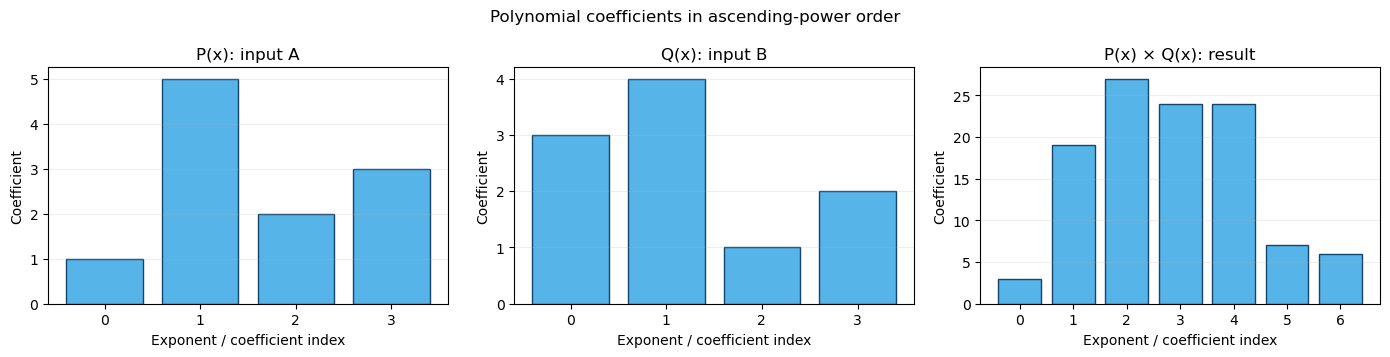

In [8]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import ListedColormap
A=[1,5,2,3]; B=[3,4,1,2]
C=poly_mul_v1_schoolbook(A,B)
fig,axes=plt.subplots(1,3,figsize=(14,3.6))
for ax,values,title in zip(axes,[A,B,C],['P(x): input A','Q(x): input B','P(x) × Q(x): result']):
    ax.bar(range(len(values)),values,color='#56B4E9',edgecolor='#16456B')
    ax.set_title(title);ax.set_xlabel('Exponent / coefficient index');ax.set_ylabel('Coefficient');ax.set_xticks(range(len(values)));ax.grid(axis='y',alpha=.2)
fig.suptitle('Polynomial coefficients in ascending-power order');plt.tight_layout();plt.show()

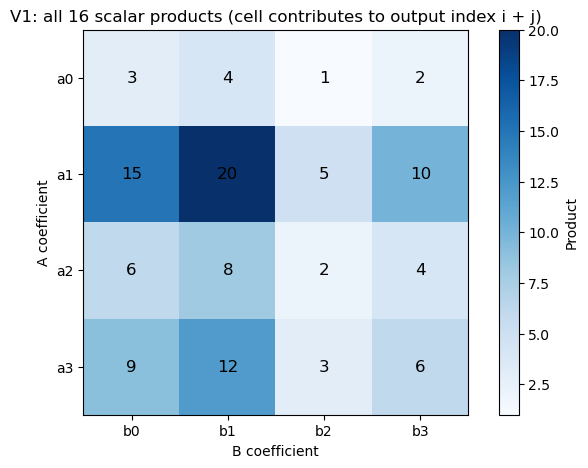

In [9]:
fig,ax=plt.subplots(figsize=(8,5))
products=np.outer(A,B)
im=ax.imshow(products,cmap='Blues')
for i in range(len(A)):
    for j in range(len(B)):
        ax.text(j,i,str(products[i,j]),ha='center',va='center',color='black',fontsize=12)
ax.set_xticks(range(len(B)),[f'b{j}' for j in range(len(B))]);ax.set_yticks(range(len(A)),[f'a{i}' for i in range(len(A))]);ax.set_xlabel('B coefficient');ax.set_ylabel('A coefficient');ax.set_title('V1: all 16 scalar products (cell contributes to output index i + j)');plt.colorbar(im,ax=ax,label='Product');plt.show()

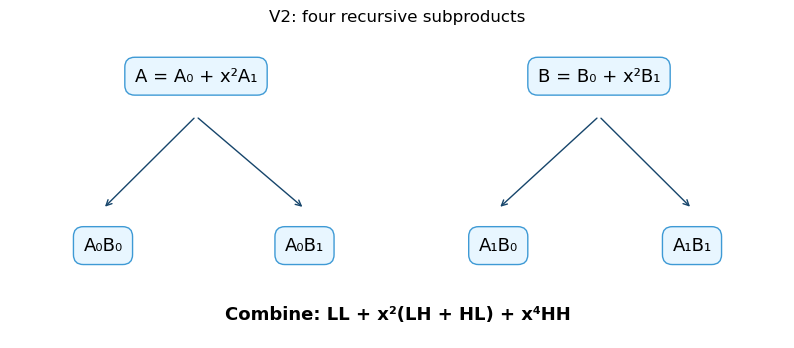

In [10]:
fig,ax=plt.subplots(figsize=(10,4))
ax.axis('off')
labels=[('A = A₀ + x²A₁',(0.24,.85)),('B = B₀ + x²B₁',(0.76,.85)),('A₀B₀',(.12,.3)),('A₀B₁',(.38,.3)),('A₁B₀',(.63,.3)),('A₁B₁',(.88,.3))]
for t,(x,y) in labels:
    ax.text(x,y,t,ha='center',va='center',fontsize=13,bbox=dict(boxstyle='round,pad=.55',fc='#E8F6FF',ec='#3E9AD5'))
for x in [.12,.38]:ax.annotate('',xy=(x,.42),xytext=(.24,.72),arrowprops=dict(arrowstyle='->',color='#16456B'))
for x in [.63,.88]:ax.annotate('',xy=(x,.42),xytext=(.76,.72),arrowprops=dict(arrowstyle='->',color='#16456B'))
ax.text(.5,.06,'Combine: LL + x²(LH + HL) + x⁴HH',ha='center',fontsize=13,fontweight='bold');ax.set_title('V2: four recursive subproducts');plt.show()

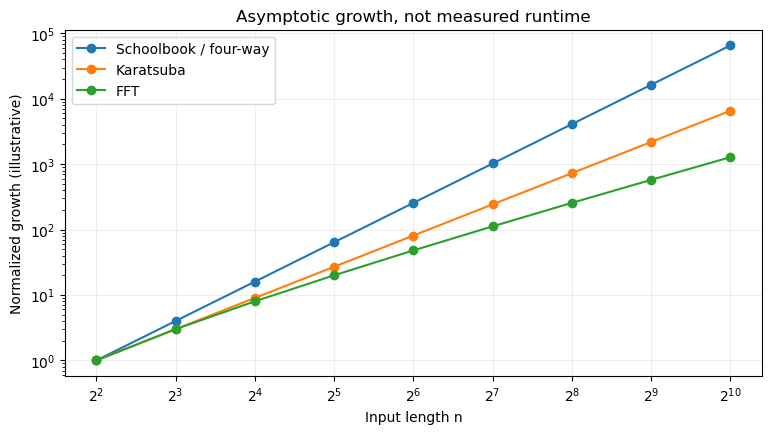

In [11]:
n=np.array([2**k for k in range(2,11)])
fig,ax=plt.subplots(figsize=(9,4.5))
for name,y in [('Schoolbook / four-way',n**2),('Karatsuba',n**np.log2(3)),('FFT',n*np.log2(n))]:ax.plot(n,y/y[0],marker='o',label=name)
ax.set_xscale('log',base=2);ax.set_yscale('log');ax.set_xlabel('Input length n');ax.set_ylabel('Normalized growth (illustrative)');ax.set_title('Asymptotic growth, not measured runtime');ax.grid(alpha=.2);ax.legend();plt.show()

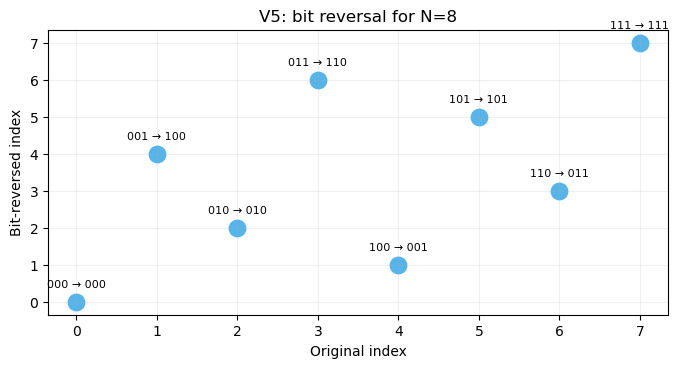

Swap pairs: [(1, 4), (3, 6)]


In [12]:
N=8; bits=3
rev=[int(f'{i:0{bits}b}'[::-1],2) for i in range(N)]
fig,ax=plt.subplots(figsize=(8,3.7));ax.scatter(range(N),rev,s=140,color='#56B4E9');
for i,j in enumerate(rev):ax.annotate(f'{i:03b} → {j:03b}',(i,j),xytext=(0,10),textcoords='offset points',ha='center',fontsize=8)
ax.set_xticks(range(N));ax.set_yticks(range(N));ax.set_xlabel('Original index');ax.set_ylabel('Bit-reversed index');ax.set_title('V5: bit reversal for N=8');ax.grid(alpha=.2);plt.show()
print('Swap pairs:',[(i,j) for i,j in enumerate(rev) if i<j])

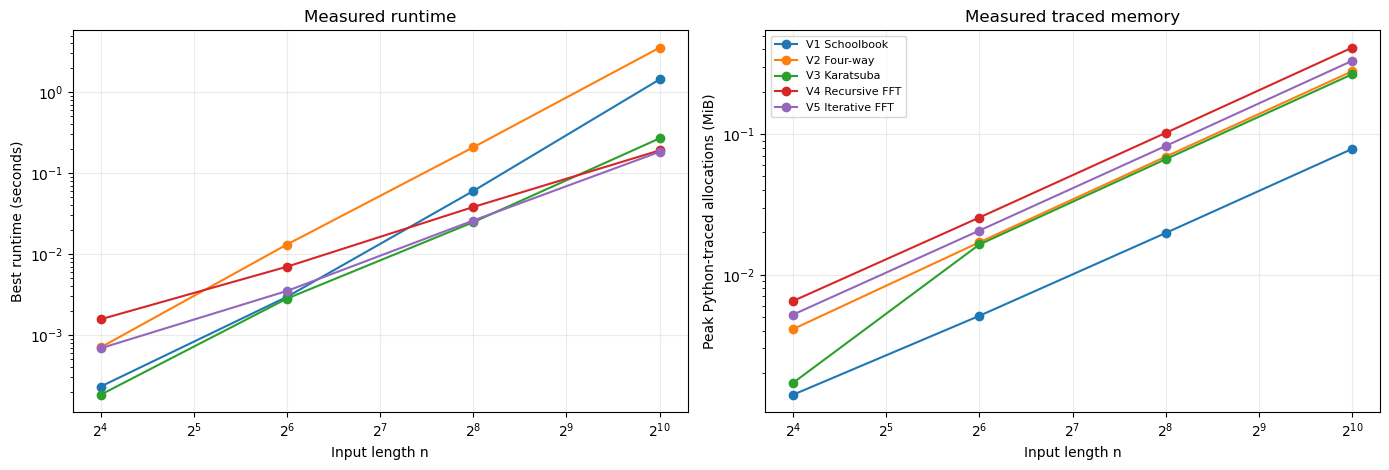

Benchmark data from Tara CSV; measured samples, not theoretical curves.


In [13]:
import csv, os
csv_path='tara_runtime.csv'
if not os.path.exists(csv_path):csv_path='/mnt/data/tara_runtime.csv'
with open(csv_path,newline='') as f: rows=list(csv.DictReader(f))
fig,axes=plt.subplots(1,2,figsize=(14,4.8))
for name in dict.fromkeys(r['algorithm'] for r in rows):
    subset=sorted((r for r in rows if r['algorithm']==name),key=lambda r:int(r['input_size']))
    x=[int(r['input_size']) for r in subset]
    axes[0].plot(x,[float(r['best_runtime_seconds']) for r in subset],marker='o',label=name)
    axes[1].plot(x,[float(r['peak_traced_memory_mib']) for r in subset],marker='o',label=name)
for ax,ylabel in zip(axes,['Best runtime (seconds)','Peak Python-traced allocations (MiB)']):
    ax.set_xscale('log',base=2);ax.set_yscale('log');ax.set_xlabel('Input length n');ax.set_ylabel(ylabel);ax.grid(alpha=.25)
axes[0].set_title('Measured runtime');axes[1].set_title('Measured traced memory');axes[1].legend(fontsize=8);plt.tight_layout();plt.show()
print('Benchmark data from Tara CSV; measured samples, not theoretical curves.')

In [14]:
precision_path='tara_precision_stress.csv'
if not os.path.exists(precision_path):precision_path='/mnt/data/tara_precision_stress.csv'
with open(precision_path,newline='') as f: precision=list(csv.DictReader(f))
print('Precision CSV columns:',list(precision[0]) if precision else 'empty')
from IPython.display import display
import pandas as pd
display(pd.DataFrame(precision))
# Keep the recorded results visible without guessing the CSV schema.

Precision CSV columns: ['coefficient_magnitude', 'algorithm', 'incorrect_coefficients', 'maximum_absolute_error']


,coefficient_magnitude,algorithm,incorrect_coefficients,maximum_absolute_error
0,1000000,V4 Recursive FFT,0,0
1,1000000,V5 Iterative FFT,3492,4
2,10000000,V4 Recursive FFT,3753,3
3,10000000,V5 Iterative FFT,8121,345
4,100000000,V4 Recursive FFT,8132,274
5,100000000,V5 Iterative FFT,8191,36822
